# Лабораторная работа №4. Байесовская сеть для Titanic

Цель работы — построить сеть для данных о пассажирах «Титаника», оценить условные вероятности и выяснить, как наблюдения и структура графа влияют на ответы модели.

[Задание курса](https://github.com/lesopylka/ml_course_mai/blob/main/bayesian/lab04.pdf) · [Исходный датасет Titanic](https://www.kaggle.com/datasets/yasserh/titanic-dataset)

## 1. Данные

Одна строка описывает одного пассажира. Использовал `Pclass` (класс билета от 1 до 3), `Sex` (пол в исходной записи), `Age` (возраст в годах) и `Survived` (1 — выжил, 0 — погиб). Класс мог быть связан с расположением кают и возможностью добраться до шлюпок. Пол и возраст могли быть связаны с порядком посадки. Возрастной состав и полнота записей могли различаться между классами.

В исходном файле также есть идентификатор, имя, стоимость и номер билета, каюта, порт посадки и два счётчика родственников. Для сети выбрал четыре переменные, чтобы интерпретировать связи и сохранить достаточное число пассажиров в сочетаниях категорий.

In [1]:
from graphlib import TopologicalSorter
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.model_selection import train_test_split

raw = pd.read_csv(Path('data') / 'Titanic-Dataset.csv')
display(raw[['PassengerId', 'Pclass', 'Sex', 'Age', 'Survived']].head())
display(raw.isna().sum().to_frame('Пропуски'))
print(f'Строк: {len(raw)}. Столбцов: {raw.shape[1]}. Полных повторов: {raw.duplicated().sum()}.')
assert raw['PassengerId'].is_unique

,PassengerId,Pclass,Sex,Age,Survived
0,1,3,male,22.0,0
1,2,1,female,38.0,1
2,3,3,female,26.0,1
3,4,1,female,35.0,1
4,5,3,male,35.0,0


,Пропуски
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Строк: 891. Столбцов: 12. Полных повторов: 0.


## 2. Подготовка и вопросы

Разделил возраст на две группы с границей 16 лет: `child` — младше 16, `adult` — от 16 лет. Взял одну простую границу для сравнения детей и взрослых при эвакуации. Это рабочее определение для модели. Для 177 записей без возраста использовал состояние `unknown`, чтобы сохранить пассажиров и учесть, что наличие записи о возрасте может быть связано с классом. Если в запросе возраст вообще не указан, сеть суммирует по всем трём состояниям.

Параметры оценил на стратифицированном train (80%, `random_state=42`), а проверочные метрики посчитал на test (20%). Стратификация сохраняет долю выживших в обеих частях. Правило группировки возраста задано заранее.

Перед построением сети сформулировал три вопроса.

1. Как меняется вероятность выживания, если известно, что пассажир — женщина?
2. Как меняется вероятность выживания, если известно, что пассажир — мужчина из третьего класса?
3. Как меняется вероятность принадлежности к первому классу, если известно, что пассажирка выжила?

In [2]:
states = {
    'Pclass': [1, 2, 3],
    'Sex': ['female', 'male'],
    'AgeGroup': ['child', 'adult', 'unknown'],
    'Survived': [0, 1],
}

age_group = pd.cut(raw['Age'], [0, 16, np.inf], right=False, labels=['child', 'adult'])
data = raw.assign(AgeGroup=age_group.cat.add_categories(['unknown']).fillna('unknown'))[list(states)]
train, test = train_test_split(data, test_size=0.2, random_state=42, stratify=data['Survived'])
assert train.index.intersection(test.index).empty

display(pd.DataFrame({
    'Строк': [len(train), len(test)],
    'Выжили': [train['Survived'].sum(), test['Survived'].sum()],
}, index=['train', 'test']))
state_counts = pd.concat({column: train[column].value_counts().reindex(values) for column, values in states.items()})
display(state_counts.rename_axis(['Узел', 'Состояние']).to_frame('Число в train'))

,Строк,Выжили
train,712,273
test,179,69


Число в train
Узел     Состояние               
Pclass   1                    171
         2                    150
         3                    391
Sex      female               253
         male                 459
AgeGroup child                 66
         adult                509
         unknown              137
Survived 0                    439
         1                    273

У переменных от двух до трёх состояний. В train меньше всего детей (66 человек). Даже при таком небольшом числе состояний отдельные сочетания класса, пола и возраста встречаются редко. Их численность проверил вместе с условными вероятностями.

## 3. Структура сети

| Ребро | Предположение |
| --- | --- |
| `Pclass → AgeGroup` | Среди пассажиров разных классов могут различаться возрастной состав и доля пропущенных возрастов. Направил связь от класса к распределению записанного возраста, чтобы описать состав каждого класса. |
| `Pclass → Survived` | Класс мог быть связан с доступом к палубам и шлюпкам. Класс был известен до эвакуации. |
| `Sex → Survived` | Приоритет при посадке мог зависеть от пола. Пол известен до исхода. |
| `AgeGroup → Survived` | Дети и взрослые могли иметь разные шансы при эвакуации. Возрастная группа относится к характеристикам пассажира до исхода. |

Из графа получается совместное распределение

$$P(C,S,A,Y)=P(C)\,P(S)\,P(A\mid C)\,P(Y\mid C,S,A),$$

где $C$ — класс, $S$ — пол, $A$ — записанная возрастная группа, $Y$ — исход. Такое разложение предполагает независимость пола и класса до наблюдения исхода, а возрастной группы и пола — при известном классе. Эти допущения упрощают таблицы сети.

Топологический порядок: Pclass → Sex → AgeGroup → Survived


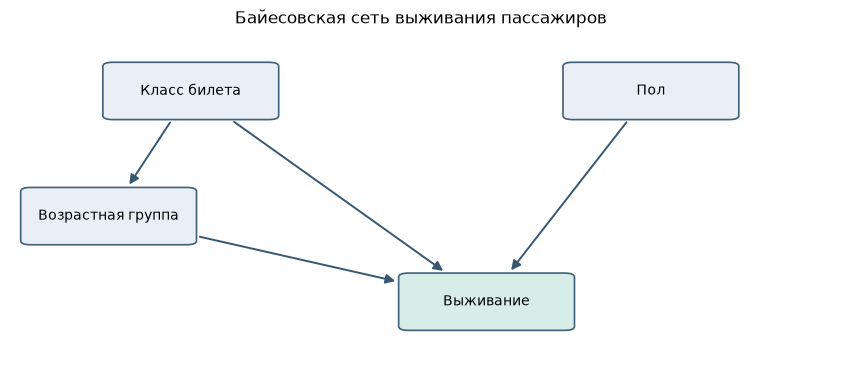

In [3]:
parents = {
    'Pclass': (),
    'Sex': (),
    'AgeGroup': ('Pclass',),
    'Survived': ('Pclass', 'Sex', 'AgeGroup'),
}
topological_order = list(TopologicalSorter(parents).static_order())
print('Топологический порядок:', ' → '.join(topological_order))

positions = {'Pclass': (0.22, 0.82), 'Sex': (0.78, 0.82),
             'AgeGroup': (0.12, 0.44), 'Survived': (0.58, 0.18)}
labels = {'Pclass': 'Класс билета', 'Sex': 'Пол',
          'AgeGroup': 'Возрастная группа', 'Survived': 'Выживание'}

fig, ax = plt.subplots(figsize=(8.3, 3.6), layout='constrained')
boxes = {}
for node, (x, y) in positions.items():
    boxes[node] = ax.add_patch(FancyBboxPatch(
        (x - 0.095, y - 0.075), 0.19, 0.15,
        boxstyle='round,pad=0.012', facecolor='#d7eee8' if node == 'Survived' else '#e9eef7',
        edgecolor='#406079', linewidth=1.2, zorder=2,
    ))
    ax.text(x, y, labels[node], ha='center', va='center', fontsize=10, zorder=3)
for node, incoming in parents.items():
    for parent in incoming:
        ax.add_patch(FancyArrowPatch(
            positions[parent], positions[node], patchA=boxes[parent], patchB=boxes[node],
            arrowstyle='-|>', mutation_scale=14, color='#375870', linewidth=1.4,
        ))
ax.set(xlim=(0, 1), ylim=(0, 1), title='Байесовская сеть выживания пассажиров')
ax.axis('off')
plt.show()

В графе класс связан с исходом напрямую и через возрастную группу. В узле выживания сходятся три стрелки, поэтому наблюдение исхода позволяет обновлять вероятности его родителей. Стрелки задают разложение совместного распределения.

## 4. Оценка параметров

Для каждого узла подсчитал число наблюдений в каждом состоянии при всех сочетаниях состояний родителей. Применил сглаживание Лапласа ($\alpha=1$): если $N_x$ — число строк в состоянии $x$ при данном наборе родителей, $N$ — общее число таких строк, а $k$ — число состояний узла, то

$$\widehat P(x\mid\mathrm{parents})=\frac{N_x+1}{N+k}.$$

Для корневых узлов формула применяется ко всему train. Сглаживание сохраняет ненулевые вероятности для состояний, которых в небольшой группе могло не оказаться.

In [4]:
def fit_tables(data, graph):
    tables = {}
    for node, incoming in graph.items():
        columns = [*incoming, node]
        combinations = pd.MultiIndex.from_product([states[column] for column in columns], names=columns)
        counts = data.groupby(columns, observed=True).size()
        if not incoming:
            counts.index = pd.MultiIndex.from_arrays([counts.index], names=columns)
        counts = counts.reindex(combinations, fill_value=0)
        support = counts.groupby(level=list(incoming)).transform('sum') if incoming else counts.sum()
        probability = (counts + 1) / (support + len(states[node]))
        tables[node] = pd.DataFrame({'count': counts, 'support': support, 'p': probability})
    return tables


tables = fit_tables(train, parents)
for node, table in tables.items():
    incoming = parents[node]
    totals = table['p'].groupby(level=list(incoming)).sum() if incoming else table['p'].sum()
    assert np.allclose(totals, 1)

age_table = tables['AgeGroup'].reset_index()
age_table['Доля в train'] = age_table['count'] / age_table['support']
age_table = age_table.rename(columns={'p': 'Вероятность сети'})
display(age_table.pivot(index='Pclass', columns='AgeGroup', values=['Доля в train', 'Вероятность сети']).round(3))

survival_table = tables['Survived'].xs(1, level='Survived').copy()
survival_table['observed'] = survival_table['count'] / survival_table['support']
display(survival_table[['support', 'count', 'observed', 'p']].rename(columns={
    'support': 'Всего', 'count': 'Выжили', 'observed': 'Доля в train', 'p': 'Вероятность сети',
}).round(3))

Доля в train                Вероятность сети               
AgeGroup        child  adult unknown            child  adult unknown
Pclass                                                              
1               0.018  0.830   0.152            0.023  0.822   0.155
2               0.107  0.833   0.060            0.111  0.824   0.065
3               0.120  0.619   0.261            0.122  0.617   0.261

Всего  Выжили  Доля в train  Вероятность сети
Pclass Sex    AgeGroup                                               
1      female child         1       1         1.000             0.667
              adult        70      68         0.971             0.958
              unknown       8       8         1.000             0.900
       male   child         2       2         1.000             0.750
              adult        72      28         0.389             0.392
              unknown      18       4         0.222             0.250
2      female child         8       8         1.000             0.900
              adult        49      44         0.898             0.882
              unknown       1       1         1.000             0.667
       male   child         8       8         1.000             0.900
              adult        76       5         0.066             0.077
              unknown       8       1         0.125             0.200
3      female child        26      14         0.538             0.536
              adult        60      25         0.417             0.419
              unknown      30      19         0.633             0.625
       male   child        21       6         0.286             0.304
              adult       182      24         0.132             0.136
              unknown      72       7         0.097             0.108

В третьем классе возраст не записан у 102 из 391 пассажира (26,1%), а во втором — у 9 из 150 (6,0%). После сглаживания оценки почти те же, 26,1% и 6,5%. Разница показывает, почему класс полезно учитывать при оценке распределения записанного возраста.

Среди взрослых мужчин доля выживших в первом классе — 28 из 72 (38,9%), а в третьем — 24 из 182 (13,2%). Вероятности сети составляют 39,2% и 13,6%. Во втором классе выжили все восемь мальчиков, но оценка сети равна 90%. В первом классе для мальчиков всего два наблюдения, поэтому два выживших дают уже 75%. Разница между 90% и 75% в этих группах во многом определяется их размером.

## 5. Точный вероятностный вывод

Для четырёх узлов существует $3\cdot2\cdot3\cdot2=36$ совместных состояний. Для каждого перемножил четыре вероятности из таблиц. При запросе отобрал состояния, совместимые с наблюдениями, сложил их вероятности по значениям искомой переменной и разделил на $P(\text{наблюдения})$. Так можно вычислить как вероятность выживания, так и вероятность класса при известном исходе.

In [5]:
def joint_distribution(graph, cpts):
    rows = []
    for values in product(*states.values()):
        assignment = dict(zip(states, values))
        factors = []
        for node, incoming in graph.items():
            key = tuple(assignment[parent] for parent in incoming) + (assignment[node],)
            factors.append(cpts[node].at[key, 'p'])
        rows.append({**assignment, 'p': np.prod(factors)})
    joint = pd.DataFrame(rows)
    assert np.isclose(joint['p'].sum(), 1)
    return joint


def select_evidence(frame, evidence):
    selected = frame
    for column, value in evidence.items():
        selected = selected.loc[selected[column].eq(value)]
    return selected


def query(joint, variable, evidence):
    selected = select_evidence(joint, evidence)
    mass = selected.groupby(variable)['p'].sum().reindex(states[variable], fill_value=0)
    return mass / mass.sum()


def compare_query(joint, variable, value, evidence):
    observed = select_evidence(train, evidence)
    prior = query(joint, variable, {})[value]
    posterior = query(joint, variable, evidence)[value]
    return [prior, posterior, 100 * (posterior - prior), len(observed), observed[variable].eq(value).mean()]


joint = joint_distribution(parents, tables)
questions = {
    'Выживание женщины': ('Survived', 1, {'Sex': 'female'}),
    'Выживание мужчины 3-го класса': ('Survived', 1, {'Sex': 'male', 'Pclass': 3}),
    '1-й класс у выжившей женщины': ('Pclass', 1, {'Sex': 'female', 'Survived': 1}),
}
answers = pd.DataFrame.from_dict(
    {label: compare_query(joint, *request) for label, request in questions.items()}, orient='index',
    columns=['До', 'После', 'Разница, п. п.', 'Число строк train', 'Доля при условии в train'],
)
display(answers.round(3))
display(pd.crosstab(train['Pclass'], train['Sex'], normalize='index').round(3))

,До,После,"Разница, п. п.",Число строк train,Доля при условии в train
Выживание женщины,0.376,0.678,30.132,253,0.743
Выживание мужчины 3-го класса,0.376,0.149,-22.722,275,0.135
1-й класс у выжившей женщины,0.241,0.335,9.403,188,0.410


Sex,female,male
Pclass,,
1,0.462,0.538
2,0.387,0.613
3,0.297,0.703


1. При наблюдении `Sex=female` вероятность выживания выросла с 37,6% до 67,8%. В train выжили 74,3% женщин. Среди пассажиров первого класса женщины составляют 46,2%, а третьего — 29,7%. Сеть предполагает, что пол и класс априорно независимы. При запросе о женщинах она усредняет вероятности по распределению классов всех пассажиров, где доля третьего класса выше, чем среди женщин.
2. Для мужчины третьего класса вероятность выживания снизилась с 37,6% до 14,9%. В train при таком условии выжили 13,5%. Возраст не задан, поэтому модель усредняет вероятности по возрастным группам третьего класса.
3. Для выжившей женщины вероятность первого класса выросла с 24,1% до 33,5%. Это обратный вывод: известный исход меняет оценку класса, поскольку выживание в сети зависит от класса. В train доля первого класса при таком условии равна 41,0%. На расхождение влияет упрощение зависимости между полом и классом.

## 6. Последовательное добавление наблюдений

Рассмотрел выживание одного условного пассажира. Сначала о нём ничего не известно, затем становится известно, что это мужчина из третьего класса младше 16 лет. На каждом шаге оставил предыдущие наблюдения и пересчитал оба состояния `Survived`.

,Погиб,Выжил
Без наблюдений,0.624,0.376
Мужчина,0.790,0.210
+ 3-й класс,0.851,0.149
+ Младше 16 лет,0.696,0.304


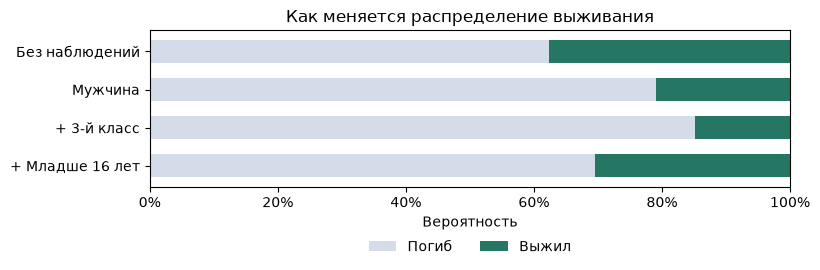

In [6]:
scenarios = {
    'Без наблюдений': {},
    'Мужчина': {'Sex': 'male'},
    '+ 3-й класс': {'Sex': 'male', 'Pclass': 3},
    '+ Младше 16 лет': {'Sex': 'male', 'Pclass': 3, 'AgeGroup': 'child'},
}
evidence_results = pd.DataFrame({name: query(joint, 'Survived', evidence) for name, evidence in scenarios.items()}).T
evidence_results.columns = ['Погиб', 'Выжил']
display(evidence_results.round(3))

ax = evidence_results.plot.barh(stacked=True, color=['#d5dce9', '#267664'], figsize=(8.3, 3.0), width=0.60)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlim=(0, 1), xlabel='Вероятность', title='Как меняется распределение выживания')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.26), ncols=2, frameon=False)
ax.figure.tight_layout()
plt.show()

Вероятность выживания изменилась по шагам: **37,6% → 21,0% → 14,9% → 30,4%**. Когда стал известен пол, сеть использовала распределения исхода для мужчин. Третий класс снизил оценку через прямую связь с исходом и через распределение возрастных групп. Наблюдение `AgeGroup=child` уточнило, какую строку таблицы выживания использовать. В train выжили 6 из 21 мальчика третьего класса, а после сглаживания получилось $(6+1)/(21+2)\approx30{,}4\%$.

## 7. Удаление ребра

Убрал ребро `Pclass → Survived` и заново оценил таблицы на том же train. В упрощённой сети вероятность выживания зависит от пола и возрастной группы. Между классом и исходом сохраняется путь `Pclass → AgeGroup → Survived`, поэтому класс по-прежнему может менять ответ, если возраст не указан. Повторил второй запрос и дополнительно зафиксировал возрастную группу, чтобы проверить, как ведёт себя этот путь.

In [7]:
reduced_parents = {**parents, 'Survived': ('Sex', 'AgeGroup')}
reduced_joint = joint_distribution(reduced_parents, fit_tables(train, reduced_parents))

comparison = {
    'Мужчина, 3-й класс': scenarios['+ 3-й класс'],
    'Взрослый мужчина, 3-й класс': {'Sex': 'male', 'AgeGroup': 'adult', 'Pclass': 3},
    'Взрослый мужчина, 1-й класс': {'Sex': 'male', 'AgeGroup': 'adult', 'Pclass': 1},
}
structure_results = pd.DataFrame({
    'Полная сеть': [query(joint, 'Survived', evidence)[1] for evidence in comparison.values()],
    'Без ребра': [query(reduced_joint, 'Survived', evidence)[1] for evidence in comparison.values()],
}, index=comparison)
assert np.isclose(structure_results['Без ребра'].iloc[1], structure_results['Без ребра'].iloc[2])
display(structure_results.round(3))

,Полная сеть,Без ребра
"Мужчина, 3-й класс",0.149,0.204
"Взрослый мужчина, 3-й класс",0.136,0.175
"Взрослый мужчина, 1-й класс",0.392,0.175


Для мужчины третьего класса с неизвестным в запросе возрастом оценка выросла с 14,9% до 20,4%. После удаления ребра таблица выживания объединила пассажиров всех классов внутри каждой комбинации пола и возрастной группы. При известном взрослом возрасте оценка для мужчин первого и третьего классов стала одинаковой (17,5%). Фиксация возрастной группы перекрыла оставшийся путь от класса к исходу.

## 8. Проверка вероятностей на test

Для каждого пассажира из test использовал его класс, пол и записанную возрастную группу как наблюдения. Для сравнения взял константный baseline с долей выживших на train. Посчитал Brier score (средний квадрат ошибки вероятности) и log loss (штрафует уверенные ошибки сильнее). У обеих метрик меньшее значение лучше.

In [8]:
def test_probabilities(joint):
    evidence_columns = ['Pclass', 'Sex', 'AgeGroup']
    cases = test[evidence_columns].drop_duplicates()
    probabilities = [
        query(joint, 'Survived', dict(zip(evidence_columns, values)))[1]
        for values in cases.itertuples(index=False, name=None)
    ]
    return test.merge(cases.assign(probability=probabilities), on=evidence_columns,
                      how='left', validate='many_to_one')['probability'].to_numpy()


predictions = {
    'Baseline': np.full(len(test), train['Survived'].mean()),
    'Полная сеть': test_probabilities(joint),
    'Сеть без ребра': test_probabilities(reduced_joint),
}
metrics = pd.DataFrame({
    name: {'Brier score': brier_score_loss(test['Survived'], p), 'Log loss': log_loss(test['Survived'], p)}
    for name, p in predictions.items()
}).T
display(metrics.round(4))

,Brier score,Log loss
Baseline,0.2369,0.6667
Полная сеть,0.1414,0.4376
Сеть без ребра,0.1641,0.5075


На test полная сеть получила Brier score 0,1414 и log loss 0,4376. У baseline значения 0,2369 и 0,6667. Удаление прямой связи класса с выживанием ухудшило обе метрики, до 0,1641 и 0,5075 соответственно.

## 9. Причинность и выводы

Эту сеть использовал как вероятностную модель наблюдений. Направление рёбер к выживанию обосновано порядком событий и гипотезой о ходе эвакуации. По таблице пассажиров нельзя уверенно установить причинное направление всех связей. Например, стрелка от класса к возрастной группе описывает состав групп и полноту записей. Для причинных выводов о выживании нужны дополнительные сведения о ходе эвакуации, доступе к палубам и факторах, связанных и с классом, и с исходом.

По сети оценил выживание при разных наборах сведений и смог сделать обратный вывод о классе при известном исходе. В примере мужчины третьего класса информация о возрасте почти удвоила оценку выживания. Удаление прямой связи класса с исходом выровняло оценки для взрослых мужчин разных классов. На точность ответов влияют малочисленные группы, пропуски возраста, выбранная граница 16 лет и допущение о независимости пола и класса.